# Create data set

In [7]:
import zipfile
import xml.etree.ElementTree as ET
from datetime import date
import pandas as pd

WP = "21"
XML_ZIP = "../datasets/MdB-Stammdaten.zip"

with zipfile.ZipFile(XML_ZIP) as z:
    xml_name = next(n for n in z.namelist() if n.lower().endswith(".xml"))
    root = ET.fromstring(z.read(xml_name))

def flat(el, prefix="", skip=()):
    """All direct child tags of el as {prefix+tag: text}."""
    out = {}
    if el is None:
        return out
    for c in el:
        if c.tag in skip:
            continue
        out[prefix + c.tag] = (c.text or "").strip() or None
    return out

today = date.today()
rows, inst_rows = [], []

for mdb in root.iter("MDB"):
    wp = next((w for w in mdb.iter("WAHLPERIODE") if w.findtext("WP") == WP), None)
    if wp is None or (wp.findtext("MDBWP_BIS") or "").strip():
        continue                                  # not in WP21 / already left
    bio = mdb.find("BIOGRAFISCHE_ANGABEN")
    if (bio.findtext("STERBEDATUM") or "").strip():
        continue                                  # deceased

    names = mdb.findall("NAMEN/NAME")
    name = next((n for n in names
                 if not (n.findtext("HISTORIE_BIS") or "").strip()), names[-1])

    d, m, y = map(int, bio.findtext("GEBURTSDATUM").split("."))
    age = today.year - y - ((today.month, today.day) < (m, d))

    mid = mdb.findtext("ID")
    row = {"ID": mid}
    row.update(flat(name, "NAME_"))
    row.update(flat(bio))                         # Familienstand, Religion, Beruf, Vita, ...
    row.update(flat(wp, "WP_", skip=("INSTITUTIONEN",)))
    row["Age"] = age
    row["Name"] = f"{row['NAME_VORNAME']} {row['NAME_NACHNAME']}"

    # Faction as its own column, everything else goes to the long table
    for ins in wp.findall("INSTITUTIONEN/INSTITUTION"):
        rec = {"ID": mid, "Name": row["Name"], **flat(ins)}
        inst_rows.append(rec)
        if rec.get("INSART_LANG") == "Fraktion/Gruppe":
            row["Faktion"] = rec.get("INS_LANG")
    rows.append(row)

df = pd.DataFrame(rows)
inst = pd.DataFrame(inst_rows)

# Keep the empty-string columns out of the way but don't lose them
df = df.dropna(axis=1, how="all")

print(len(df), "members,", df.shape[1], "columns")
print(df.columns.tolist())
df.to_csv("../datasets/Bundestag_MPs.csv", index=False, encoding="utf-8-sig")
inst.to_csv("../datasets/Bundestag_MPs_institutions.csv", index=False, encoding="utf-8-sig")

630 members, 28 columns
['ID', 'NAME_NACHNAME', 'NAME_VORNAME', 'NAME_ORTSZUSATZ', 'NAME_ADEL', 'NAME_PRAEFIX', 'NAME_ANREDE_TITEL', 'NAME_AKAD_TITEL', 'NAME_HISTORIE_VON', 'GEBURTSDATUM', 'GEBURTSORT', 'GEBURTSLAND', 'GESCHLECHT', 'FAMILIENSTAND', 'RELIGION', 'BERUF', 'PARTEI_KURZ', 'VITA_KURZ', 'WP_WP', 'WP_MDBWP_VON', 'WP_WKR_NUMMER', 'WP_WKR_NAME', 'WP_WKR_LAND', 'WP_LISTE', 'WP_MANDATSART', 'Age', 'Name', 'Faktion']


In [9]:
df.head(10)

,ID,NAME_NACHNAME,NAME_VORNAME,NAME_ORTSZUSATZ,NAME_ADEL,NAME_PRAEFIX,NAME_ANREDE_TITEL,NAME_AKAD_TITEL,NAME_HISTORIE_VON,GEBURTSDATUM,...,WP_WP,WP_MDBWP_VON,WP_WKR_NUMMER,WP_WKR_NAME,WP_WKR_LAND,WP_LISTE,WP_MANDATSART,Age,Name,Faktion
0,11000756,Gysi,Gregor,None,None,None,Dr.,Dr.,03.10.1990,16.01.1948,...,21,25.03.2025,83,Berlin-Treptow-Köpenick,BE,BE,Direktwahl,78,Gregor Gysi,Fraktion Die Linke
1,11002718,Laschet,Armin,None,None,None,None,None,10.11.1994,18.02.1961,...,21,25.03.2025,86,Aachen I,NW,NW,Direktwahl,65,Armin Laschet,Fraktion der Christlich Demokratischen Union/C...
2,11002720,Lemke,Steffi,None,None,None,None,None,10.11.1994,19.01.1968,...,21,25.03.2025,70,Anhalt – Dessau – Wittenberg,ST,ST,Landesliste,58,Steffi Lemke,Fraktion BÜNDNIS 90/DIE GRÜNEN
3,11002733,Meister,Michael,None,None,None,Dr.,Dr.,10.11.1994,09.06.1961,...,21,25.03.2025,187,Bergstraße,HE,HE,Direktwahl,65,Michael Meister,Fraktion der Christlich Demokratischen Union/C...
4,11002735,Merz,Friedrich,None,None,None,None,None,10.11.1994,11.11.1955,...,21,25.03.2025,146,Hochsauerlandkreis,NW,NW,Direktwahl,70,Friedrich Merz,Fraktion der Christlich Demokratischen Union/C...
5,11002754,Rachel,Thomas,None,None,None,None,None,10.11.1994,17.05.1962,...,21,25.03.2025,89,Düren,NW,NW,Direktwahl,64,Thomas Rachel,Fraktion der Christlich Demokratischen Union/C...
6,11002765,Röttgen,Norbert,None,None,None,Dr.,Dr.,10.11.1994,02.07.1965,...,21,25.03.2025,97,Rhein-Sieg-Kreis II,NW,NW,Direktwahl,61,Norbert Röttgen,Fraktion der Christlich Demokratischen Union/C...
7,11003034,Bartsch,Dietmar,None,None,None,Dr.,Dr.,26.10.1998,31.03.1958,...,21,25.03.2025,14,Rostock – Landkreis Rostock II,MV,MV,Landesliste,68,Dietmar Bartsch,Fraktion Die Linke
8,11003132,Göring-Eckardt,Katrin,None,None,None,None,None,11.04.2003,03.05.1966,...,21,25.03.2025,192,Erfurt – Weimar – Weimarer Land II,TH,TH,Landesliste,60,Katrin Göring-Eckardt,Fraktion BÜNDNIS 90/DIE GRÜNEN
9,11003142,Heil,Hubertus,(Peine),None,None,None,None,26.10.1998,03.11.1972,...,21,25.03.2025,45,Gifhorn – Peine,NI,NI,Direktwahl,54,Hubertus Heil,Fraktion der Sozialdemokratischen Partei Deuts...


In [12]:
import os, re, time, unicodedata, requests
from urllib.parse import urljoin, urlparse
from bs4 import BeautifulSoup
import pandas as pd

BASE = "https://www.bundestag.de"
LIST_URL = BASE + "/ajax/filterlist/de/abgeordnete/1040594-1040594"
UA = {"User-Agent": "bundestag-dataset/0.1 (your@email.example)"}  # real contact
IMG_DIR = "../datasets/official-images"
os.makedirs(IMG_DIR, exist_ok=True)

def norm(s):
    s = (s or "").lower()
    for a, b in (("ä", "ae"), ("ö", "oe"), ("ü", "ue"), ("ß", "ss")):
        s = s.replace(a, b)
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z]+", " ", s).strip()

# 1) Fetch the full member list
r = requests.get(LIST_URL, params={"offset": 0, "all": "true", "view": "cards"},
                 headers=UA, timeout=60)
r.raise_for_status()
soup = BeautifulSoup(r.text, "html.parser")
LINK = 'a[href*="/abgeordnete/biografien/"]'

def card_of(a):
    """Climb up until the parent contains more than one member link."""
    node = a
    while node.parent is not None:
        hrefs = {x["href"] for x in node.parent.select(LINK)}
        if len(hrefs) > 1:
            break
        node = node.parent
    return node

def img_url(card):
    urls = []
    for tag in card.find_all(["img", "source"]):
        for attr in ("data-src", "data-srcset", "srcset", "src"):
            v = tag.get(attr)
            if v and not v.startswith("data:"):
                urls.append(urljoin(BASE, v.split(",")[0].split()[0]))
    return next((u for u in urls if "/resource/image/" in u), urls[0] if urls else None)

cards = {}
for a in soup.select(LINK):
    cards.setdefault(urljoin(BASE, a["href"]), card_of(a))

records = []
for href, card in cards.items():
    slug = urlparse(href).path.rsplit("/", 1)[-1]          # e.g. abdi_sanae-1043330
    m = re.match(r"(.+)-(\d+)$", slug)
    parts = [p for p in card.get_text("|", strip=True).split("|") if p]
    records.append({
        "profile": href,
        "tokens": set(norm(m.group(1) if m else slug).split()),
        "faction": parts[1] if len(parts) > 1 else None,
        "credit": next((p for p in parts if p.startswith("©")), None),
        "img": img_url(card),
    })

print(len(records), "cards found,", sum(1 for x in records if x["img"]), "with image URL")
print(str(next(iter(cards.values())))[:1500])   # sanity check of the raw HTML

# 2) Match cards to your dataframe by name tokens
def best(row):
    t = set(norm(f"{row.NAME_VORNAME} {row.NAME_NACHNAME}").split())
    cands = [x for x in records if x["tokens"] and (x["tokens"] <= t or t <= x["tokens"])]
    if len(cands) > 1:
        top = max(len(x["tokens"] & t) for x in cands)
        cands = [x for x in cands if len(x["tokens"] & t) == top]
    return cands[0] if len(cands) == 1 else None

matches = df.apply(best, axis=1)
df["BT_Profile"]  = matches.map(lambda x: x and x["profile"])
df["BT_ImageURL"] = matches.map(lambda x: x and x["img"])
df["BT_Credit"]   = matches.map(lambda x: x and x["credit"])
print(f"{df.BT_ImageURL.notna().sum()}/{len(df)} matched")

# 3) Download, named by your Stammdaten ID, resumable, polite
def download(row):
    url = row["BT_ImageURL"]
    if not isinstance(url, str):
        return None
    ext = os.path.splitext(urlparse(url).path)[1].lower() or ".jpg"
    path = os.path.join(IMG_DIR, f"{row['ID']}{ext}")
    if os.path.exists(path):
        return path
    for attempt in range(3):
        resp = requests.get(url, headers=UA, timeout=60)
        if resp.ok and resp.headers.get("content-type", "").startswith("image"):
            with open(path, "wb") as f:
                f.write(resp.content)
            time.sleep(1)
            return path
        time.sleep(5 * (attempt + 1))
    return None

df["BT_ImageFile"] = df.apply(download, axis=1)
df.to_csv("../datasets/Bundestag_MPs.csv", index=False, encoding="utf-8-sig")

# 4) Report the gaps
print(df.BT_ImageFile.notna().sum(), "images downloaded")
print("MPs without a match:")
print(df[df.BT_Profile.isna()][["ID", "Name"]].to_string())
used = set(df.BT_Profile.dropna())
print("Cards not matched to any MP (likely ausgeschieden/verstorben):")
print([x["profile"].rsplit("/", 1)[-1] for x in records if x["profile"] not in used])

639 cards found, 639 with image URL
<li class="m-grid__item m-biographies__result --cards" data-js-first-addition="true" data-js-result="cards">
<article aria-labelledby="profile-title2-90rquz4xn5n1vu88mefpmrcpl" class="e-teaserCardProfile --withLink">
<a aria-describedby="profile-text3-dylf8u21u3iej13bl50nbav1" aria-labelledby="profile-title2-90rquz4xn5n1vu88mefpmrcpl" class="e-teaserCardProfile__link" href="https://www.bundestag.de/abgeordnete/biografien/A/abdi_sanae-1043330">
<span aria-hidden="true" class="a-icon --intern e-teaserCardProfile__linkIcon">
<svg aria-hidden="true" focusable="false" height="24" viewbox="0 0 24 24" width="24" xmlns="http://www.w3.org/2000/svg"><path d="M12 23a11.083 11.083 0 0 0 11-11A11.084 11.084 0 0 0 11.989 1 11.07 11.07 0 0 0 1 12a11.09 11.09 0 0 0 11 11m5.716-11.011a.85.85 0 0 1-.313.647L13.65 16.4a.816.816 0 0 1-1.393-.587.83.83 0 0 1 .248-.593l1.38-1.37 1.348-1.122-2.351.086H7.104a.836.836 0 0 1 0-1.672h5.78l2.351.1-1.348-1.118-1.38-1.37a.93.93 0

In [13]:
# 1) What does the Stammdaten file say about them?
for mdb in root.iter("MDB"):
    for n in mdb.iter("NAME"):
        if n.findtext("NACHNAME") in ("Baerbock", "Habeck"):
            for w in mdb.iter("WAHLPERIODE"):
                if w.findtext("WP") == "21":
                    print(n.findtext("VORNAME"), n.findtext("NACHNAME"),
                          "von:", w.findtext("MDBWP_VON"), "bis:", w.findtext("MDBWP_BIS"))
            break

Annalena Baerbock von: 25.03.2025 bis: 30.06.2025
Robert Habeck von: 25.03.2025 bis: 31.08.2025


In [14]:
# 2) Are all unmatched cards really departed members?
used = set(df.BT_Profile.dropna())
unmatched = [h for h in cards if h not in used]
is_left = lambda h: re.search(r"ausgeschieden|verstorben", cards[h].get_text(" ", strip=True))
left  = [h for h in unmatched if is_left(h)]
other = [h for h in unmatched if not is_left(h)]
print(len(unmatched), "unmatched cards,", len(left), "marked ausgeschieden/verstorben")
print("Need a look:")
for h in other:
    print(" ", h.rsplit("/", 1)[-1])

18 unmatched cards, 5 marked ausgeschieden/verstorben
Need a look:
  breilmann_michael-1183252
  glaser_stefan-1048634
  graessle_ingeborg-1048650
  gross_karl-1044618
  huy_rose-1045152
  koller_johann-1045510
  krampe_jan-1045564
  lucassen_hans-1045876
  merendino_ottavia-1046072
  naser_christoph-1182708
  1047276-1047276
  1047906-1047906
  zschau_katrin-1048328


In [20]:
def last_names(h):
    slug = h.rsplit("/", 1)[-1]
    m = re.match(r"(.+)-\d+$", slug)
    toks = set(norm(m.group(1)).split()) if m else set()
    if not toks:   # nameless URL -> use "Lastname, Firstname" from the card text
        first = cards[h].get_text("|", strip=True).split("|")[0]
        toks = set(norm(first.split(",")[0]).split())
    return toks

ids_in_df = set(df.ID)
for h in other:
    toks = last_names(h)
    print("\n>>", h.rsplit("/", 1)[-1], "|", cards[h].get_text(" ", strip=True)[:90])
    found = False
    for mdb in root.iter("MDB"):
        wp = next((w for w in mdb.iter("WAHLPERIODE") if w.findtext("WP") == "21"), None)
        if wp is None:
            continue
        for n in mdb.iter("NAME"):
            ln = set(norm(n.findtext("NACHNAME") or "").split())
            if ln and ln <= toks:
                found = True
                print(f"   XML: {mdb.findtext('ID')} {n.findtext('VORNAME')} {n.findtext('NACHNAME')}"
                      f" | WP21 von {wp.findtext('MDBWP_VON')} bis {wp.findtext('MDBWP_BIS')}"
                      f" | in df: {mdb.findtext('ID') in ids_in_df}")
                break
    if not found:
        print("   not in the zip for WP21")


>> breilmann_michael-1183252 | Breilmann, Michael CDU/CSU Michael Breilmann © Tobias Koch
   not in the zip for WP21

>> glaser_stefan-1048634 | Glaser, Stefan CDU/CSU Stefan Glaser © Stefan Glaser / Tobias Reichert
   XML: 11005467 Vinzenz Glaser | WP21 von 25.03.2025 bis  | in df: True

>> graessle_ingeborg-1048650 | Gräßle, Dr. Inge CDU/CSU Dr. Inge Gräßle © Dr. Inge Gräßle/ Tobias Koch
   XML: 11005069 Ingeborg Gräßle | WP21 von 25.03.2025 bis  | in df: True

>> gross_karl-1044618 | Groß, Rainer AfD Rainer Groß © Rainer Groß/ Tobias Hase
   XML: 11005473 Rainer Groß | WP21 von 25.03.2025 bis  | in df: True

>> huy_rose-1045152 | Huy, Gerrit AfD Gerrit Huy © Gerrit Huy/ Marcus Vetter, Fotostudio Seefeld
   XML: 11005091 Gerrit Huy | WP21 von 25.03.2025 bis  | in df: True

>> koller_johann-1045510 | Koller, Hans CDU/CSU Hans Koller © Hans Koller/ Verena S. Mautner
   XML: 11005507 Hans Koller | WP21 von 25.03.2025 bis  | in df: True

>> krampe_jan-1045564 | Krampe, Jan Die Linke Jan

In [19]:
rec = {x["profile"]: x for x in records}
unmatched_df = df[df.BT_Profile.isna()]
pairs = []
for h in other:
    toks = last_names(h)
    rows = unmatched_df[unmatched_df.NAME_NACHNAME.map(
        lambda s: bool(set(norm(s).split())) and set(norm(s).split()) <= toks)]
    if len(rows) == 1:
        pairs.append((h, rows.index[0]))

for h, i in pairs:
    print(f"{df.at[i, 'Name']:30} <->  {h.rsplit('/', 1)[-1]}")

APPLY = True      # set True after checking the pairs above
if APPLY:
    for h, i in pairs:
        df.loc[i, ["BT_Profile", "BT_ImageURL", "BT_Credit"]] = [h, rec[h]["img"], rec[h]["credit"]]

Inge Gräßle                    <->  graessle_ingeborg-1048650
Rainer Groß                    <->  gross_karl-1044618
Gerrit Huy                     <->  huy_rose-1045152
Hans Koller                    <->  koller_johann-1045510
Rüdiger Lucassen               <->  lucassen_hans-1045876
Stella Merendino               <->  merendino_ottavia-1046072
Lisa Schubert                  <->  1047276-1047276
Mayra Vriesema                 <->  1047906-1047906


In [23]:
# 1) Download images for rows that have a URL but no file yet
todo = df[df.BT_ImageURL.notna() & df.BT_ImageFile.isna()]
print(len(todo), "images to download")
for idx, row in todo.iterrows():
    df.at[idx, "BT_ImageFile"] = download(row)

# 2) Counts
has_file = df.BT_ImageFile.map(lambda p: isinstance(p, str) and os.path.exists(p))
print(f"{len(df)} rows in df")
print(f"{has_file.sum()} with a photo on disk, {(~has_file).sum()} without")

# 3) Anyone without a photo
print(df[~has_file][["ID", "Name"]].to_string())

# 4) Any image files that don't belong to a row in df?
ids = set(df.ID.astype(str))
extra = [f for f in os.listdir(IMG_DIR) if os.path.splitext(f)[0] not in ids]
print(len(extra), "files in the image folder not in df:", extra[:10])

df.to_csv("../datasets/Bundestag_MPs.csv", index=False, encoding="utf-8-sig")

8 images to download
630 rows in df
629 with a photo on disk, 1 without
           ID           Name
514  11005511  Jan Köstering
0 files in the image folder not in df: []


In [24]:
h = next(x for x in cards if "krampe_jan" in x)
i = df.index[df.ID.astype(str) == "11005511"][0]

# sanity check: same party, same person?
print(df.at[i, "Name"], "|", df.at[i, "PARTEI_KURZ"])
print(cards[h].get_text(" | ", strip=True)[:120])

df.loc[i, ["BT_Profile", "BT_ImageURL", "BT_Credit"]] = [h, rec[h]["img"], rec[h]["credit"]]
df.at[i, "BT_ImageFile"] = download(df.loc[i])
print(df.at[i, "BT_ImageFile"])

Jan Köstering | DIE LINKE.
Krampe, Jan | Die Linke | Jan Krampe | © DBT/ Inga Haar
Bundestag_Images_official\11005511.jpg


In [25]:
if "NAME_FORMER" not in df.columns:
    df["NAME_FORMER"] = None
df.at[i, "NAME_FORMER"] = df.at[i, "Name"]          # Jan Köstering
df.at[i, "NAME_NACHNAME"] = "Krampe"
df.at[i, "Name"] = "Jan Krampe"

In [26]:
card_text = lambda h: cards[h].get_text(" ", strip=True) if isinstance(h, str) else ""
df["BT_Status"] = df.BT_Profile.map(
    lambda h: "ausgeschieden/verstorben" if re.search(r"ausgeschieden|verstorben", card_text(h)) else "aktiv")
print(df.BT_Status.value_counts())
print(df[df.BT_Status != "aktiv"][["ID", "Name", "PARTEI_KURZ"]].to_string())

BT_Status
aktiv                       626
ausgeschieden/verstorben      4
Name: count, dtype: int64
           ID             Name PARTEI_KURZ
42   11003780     Andreas Jung         CDU
66   11004056  Ansgar Heveling         CDU
111  11004317      Frank Junge         SPD
154  11004617     Ronja Kemmer         CDU


In [27]:
import shutil

def on_disk(p):
    return isinstance(p, str) and os.path.exists(p)

# 1) Keep only members with a photo
has_pic = df.BT_ImageFile.map(on_disk)
dropped = df[~has_pic]
df_final = df[has_pic].copy()
print(f"dropped {len(dropped)} rows without photo:")
print(dropped[["ID", "Name"]].to_string())

# 2) Safety check: no photo used by two different members
dups = df_final[df_final.BT_Profile.duplicated(keep=False)]
print("rows sharing a profile card (should be empty):")
print(dups[["ID", "Name", "BT_Profile"]].to_string())

# 3) Remove image files that don't belong to a remaining row
ids = set(df_final.ID.astype(str))
for f in os.listdir(IMG_DIR):
    if os.path.splitext(f)[0] not in ids:
        os.remove(os.path.join(IMG_DIR, f))
        print("removed orphan file:", f)

# 4) Verify a strict one-to-one match
files = {os.path.splitext(f)[0] for f in os.listdir(IMG_DIR)}
assert files == ids, "rows and image files don't match one-to-one"
assert df_final.ID.is_unique
print(f"OK: {len(df_final)} members, {len(files)} images, one-to-one")

# 5) Save as a new file (the old CSV stays untouched)
df_final.to_csv("../datasets/Bundestag_MPs_final.csv", index=False, encoding="utf-8-sig")

dropped 0 rows without photo:
Empty DataFrame
Columns: [ID, Name]
Index: []
rows sharing a profile card (should be empty):
Empty DataFrame
Columns: [ID, Name, BT_Profile]
Index: []
OK: 630 members, 630 images, one-to-one


# Load data and descriptive plots

In [28]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

CSV = "../datasets/Bundestag_MPs_final.csv"
IMG_DIR = "../datasets/official-images"

df = pd.read_csv(CSV, dtype={"ID": str})

# recompute age so it's current
birth = pd.to_datetime(df.GEBURTSDATUM, format="%d.%m.%Y")
t = pd.Timestamp.today()
df["Age"] = (t.year - birth.dt.year
             - ((birth.dt.month > t.month) | ((birth.dt.month == t.month) & (birth.dt.day > t.day))).astype(int))

def party_color(name):
    n = str(name).lower()
    for key, col in (("csu", "#0080c8"), ("cdu", "#2b2b2b"), ("spd", "#e3000f"), ("afd", "#009ee0"),
                     ("grün", "#46962b"), ("linke", "#be3075")):
        if key in n:
            return col
    return "#999999"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(df.shape)
df[["Name", "PARTEI_KURZ", "GESCHLECHT", "Age"]].head()

(630, 34)


,Name,PARTEI_KURZ,GESCHLECHT,Age
0,Gregor Gysi,DIE LINKE.,männlich,78
1,Armin Laschet,CDU,männlich,65
2,Steffi Lemke,BÜNDNIS 90/DIE GRÜNEN,weiblich,58
3,Michael Meister,CDU,männlich,65
4,Friedrich Merz,CDU,männlich,70


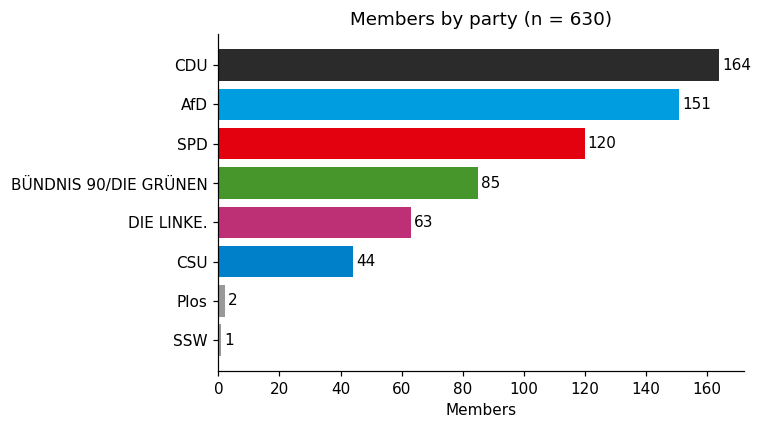

In [29]:
counts = df.PARTEI_KURZ.fillna("unknown").value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(counts.index[::-1], counts.values[::-1], color=[party_color(p) for p in counts.index[::-1]])
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 1, y, str(v), va="center")
ax.set_xlabel("Members")
ax.set_title(f"Members by party (n = {len(df)})")
plt.tight_layout(); plt.show()

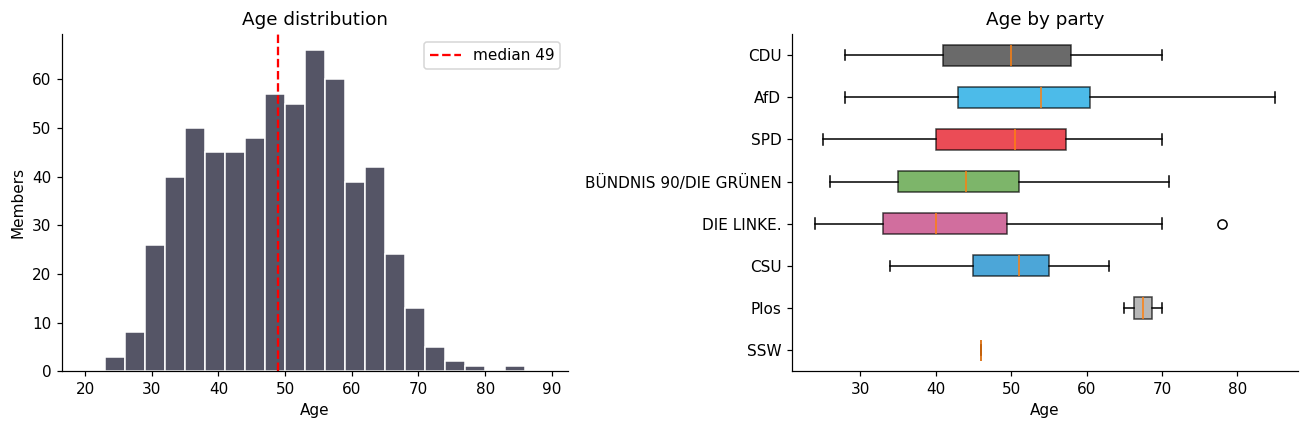

                       count  mean  median  min  max
PARTEI_KURZ                                         
AfD                      151  52.3    54.0   28   85
BÜNDNIS 90/DIE GRÜNEN     85  43.7    44.0   26   71
CDU                      164  49.2    50.0   28   70
CSU                       44  50.1    51.0   34   63
DIE LINKE.                63  42.7    40.0   24   78
Plos                       2  67.5    67.5   65   70
SPD                      120  49.2    50.5   25   70
SSW                        1  46.0    46.0   46   46


In [30]:
order = df.PARTEI_KURZ.fillna("unknown").value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df.Age, bins=range(20, 90, 3), color="#556", edgecolor="white")
axes[0].axvline(df.Age.median(), color="red", ls="--", label=f"median {df.Age.median():.0f}")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Members"); axes[0].legend()
axes[0].set_title("Age distribution")

data = [df.loc[df.PARTEI_KURZ.fillna("unknown") == p, "Age"] for p in order]
bp = axes[1].boxplot(data, vert=False, patch_artist=True, tick_labels=order)
for patch, p in zip(bp["boxes"], order):
    patch.set_facecolor(party_color(p)); patch.set_alpha(0.7)
axes[1].invert_yaxis(); axes[1].set_xlabel("Age"); axes[1].set_title("Age by party")
plt.tight_layout(); plt.show()

print(df.groupby("PARTEI_KURZ").Age.agg(["count", "mean", "median", "min", "max"]).round(1))

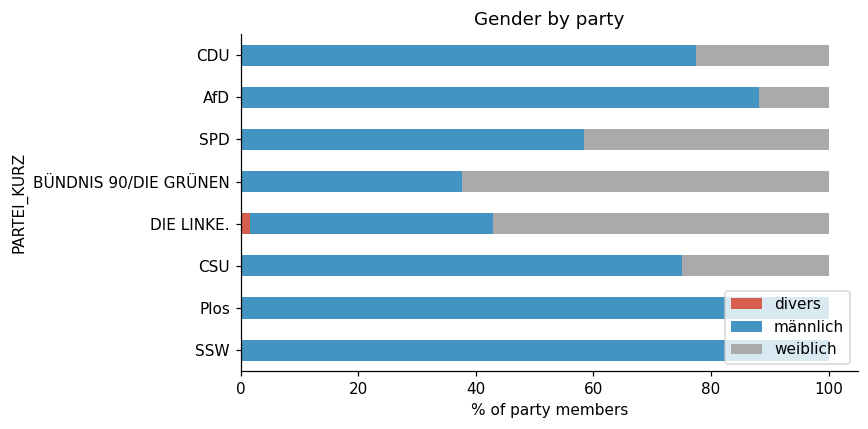

GESCHLECHT
männlich    67.3
weiblich    32.5
divers       0.2
Name: proportion, dtype: float64


In [31]:
share = pd.crosstab(df.PARTEI_KURZ.fillna("unknown"), df.GESCHLECHT, normalize="index").mul(100)
share = share.loc[order]
ax = share.plot(kind="barh", stacked=True, figsize=(8, 4), color=["#d6604d", "#4393c3", "#aaaaaa"][:share.shape[1]])
ax.invert_yaxis(); ax.set_xlabel("% of party members"); ax.set_title("Gender by party")
ax.legend(title=None, loc="lower right")
plt.tight_layout(); plt.show()

print(df.GESCHLECHT.value_counts(normalize=True).mul(100).round(1))

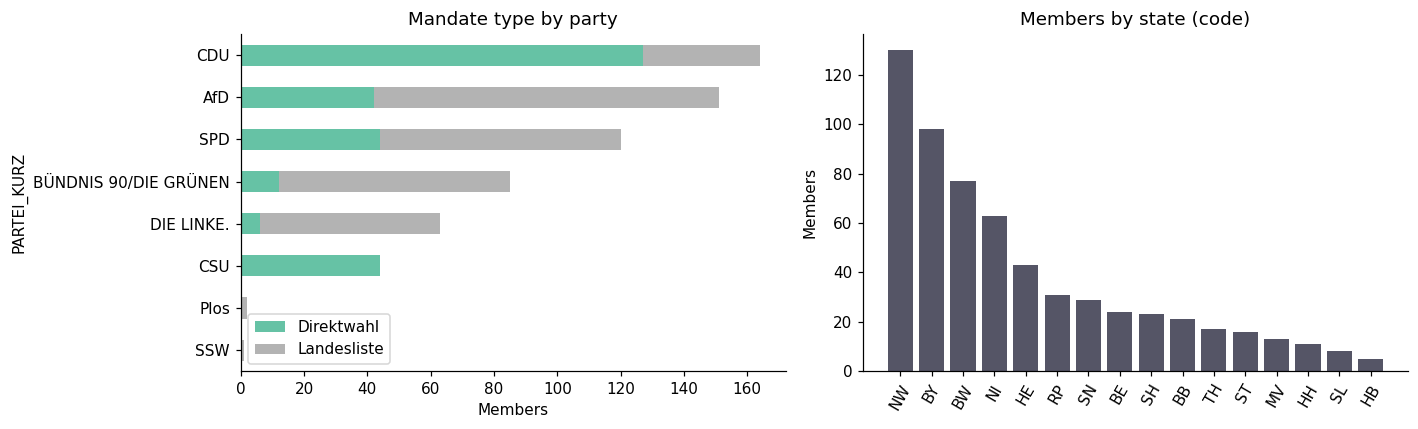

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

if "WP_MANDATSART" in df.columns:
    mand = pd.crosstab(df.PARTEI_KURZ.fillna("unknown"), df.WP_MANDATSART).loc[order]
    mand.plot(kind="barh", stacked=True, ax=axes[0], colormap="Set2")
    axes[0].invert_yaxis(); axes[0].set_xlabel("Members"); axes[0].set_title("Mandate type by party")
    axes[0].legend(title=None)

if "WP_WKR_LAND" in df.columns:
    land = df.WP_WKR_LAND.value_counts()
    axes[1].bar(land.index, land.values, color="#556")
    axes[1].set_title("Members by state (code)"); axes[1].set_ylabel("Members")
    axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [35]:
print(df[df.PARTEI_KURZ.isin(["Plos", "SSW"])][["Name", "PARTEI_KURZ", "Faktion"]].to_string())

                Name PARTEI_KURZ             Faktion
370   Stefan Seidler         SSW        Fraktionslos
503  Sieghard Knodel        Plos        Fraktionslos
597  Gerhard Trabert        Plos  Fraktion Die Linke


In [36]:
import zipfile
import xml.etree.ElementTree as ET

XML_ZIP = "../datasets/MdB-Stammdaten.zip"          # adjust the path if needed
with zipfile.ZipFile(XML_ZIP) as z:
    xml_name = next(n for n in z.namelist() if n.lower().endswith(".xml"))
    root = ET.fromstring(z.read(xml_name))

today = pd.Timestamp.today().normalize()
parse = lambda s: pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
ids = set(df.ID)

rows = []
for mdb in root.iter("MDB"):
    mid = mdb.findtext("ID")
    if mid not in ids:
        continue
    terms = []
    for w in mdb.iter("WAHLPERIODE"):
        von, bis = parse(w.findtext("MDBWP_VON")), parse(w.findtext("MDBWP_BIS"))
        if pd.isna(bis):
            bis = today                      # still sitting -> runs until today
        terms.append((int(w.findtext("WP")), von, bis))
    valid = [(wp, v, b) for wp, v, b in terms if pd.notna(v)]
    rows.append({
        "ID": mid,
        "n_terms": len(terms),
        "first_entry": min(v for _, v, _ in valid) if valid else pd.NaT,
        "first_wp": min(wp for wp, _, _ in terms),
        "years_total": sum((b - v).days for _, v, b in valid) / 365.25,
    })

tenure = pd.DataFrame(rows)
df = df.drop(columns=[c for c in tenure.columns if c != "ID" and c in df.columns]) \
       .merge(tenure, on="ID", how="left")
df["first_year"] = df.first_entry.dt.year

print(df[["n_terms", "years_total"]].describe().round(1))
print(df.n_terms.isna().sum(), "members without tenure data (should be 0)")

       n_terms  years_total
count    630.0        630.0
mean       2.5          7.3
std        1.7          6.6
min        1.0          0.6
25%        1.0          1.6
50%        2.0          5.0
75%        3.0          9.0
max       10.0         32.4
0 members without tenure data (should be 0)


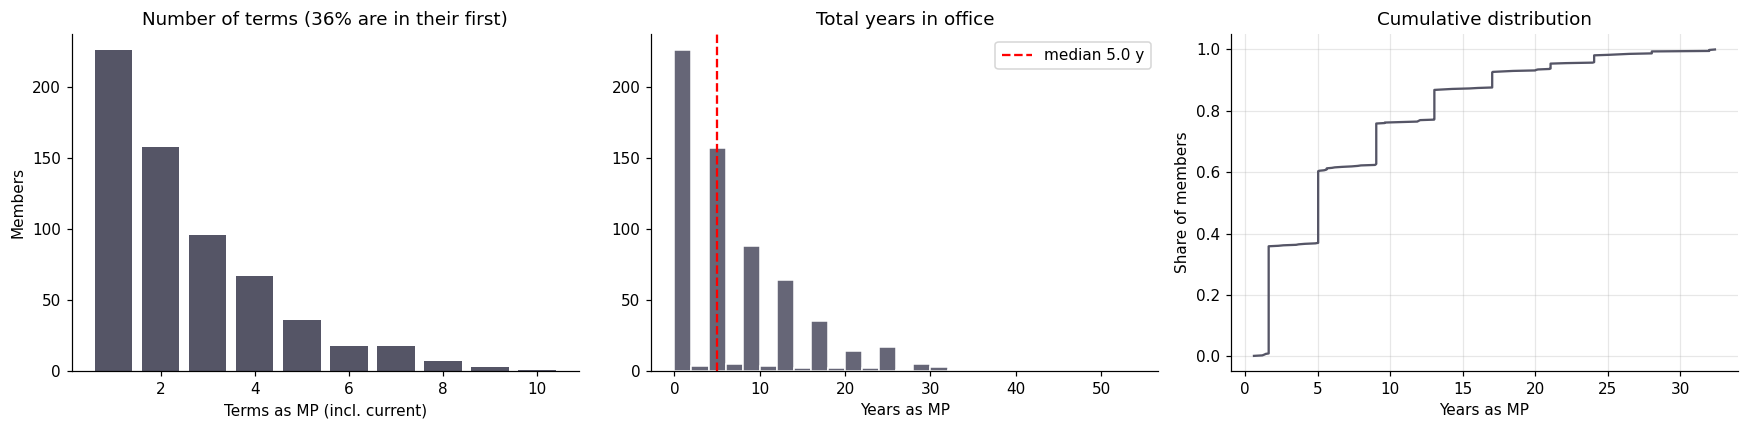

In [37]:
order = df.PARTEI_KURZ.fillna("unknown").value_counts().index
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# number of terms
tc = df.n_terms.value_counts().sort_index()
axes[0].bar(tc.index, tc.values, color="#556")
axes[0].set_xlabel("Terms as MP (incl. current)"); axes[0].set_ylabel("Members")
axes[0].set_title(f"Number of terms ({(df.n_terms == 1).mean():.0%} are in their first)")

# years in office
axes[1].hist(df.years_total, bins=range(0, 55, 2), color="#667", edgecolor="white")
axes[1].axvline(df.years_total.median(), color="red", ls="--",
                label=f"median {df.years_total.median():.1f} y")
axes[1].set_xlabel("Years as MP"); axes[1].set_title("Total years in office"); axes[1].legend()

# cumulative share
s = np.sort(df.years_total.values)
axes[2].plot(s, np.arange(1, len(s) + 1) / len(s), color="#556")
axes[2].set_xlabel("Years as MP"); axes[2].set_ylabel("Share of members")
axes[2].set_title("Cumulative distribution"); axes[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

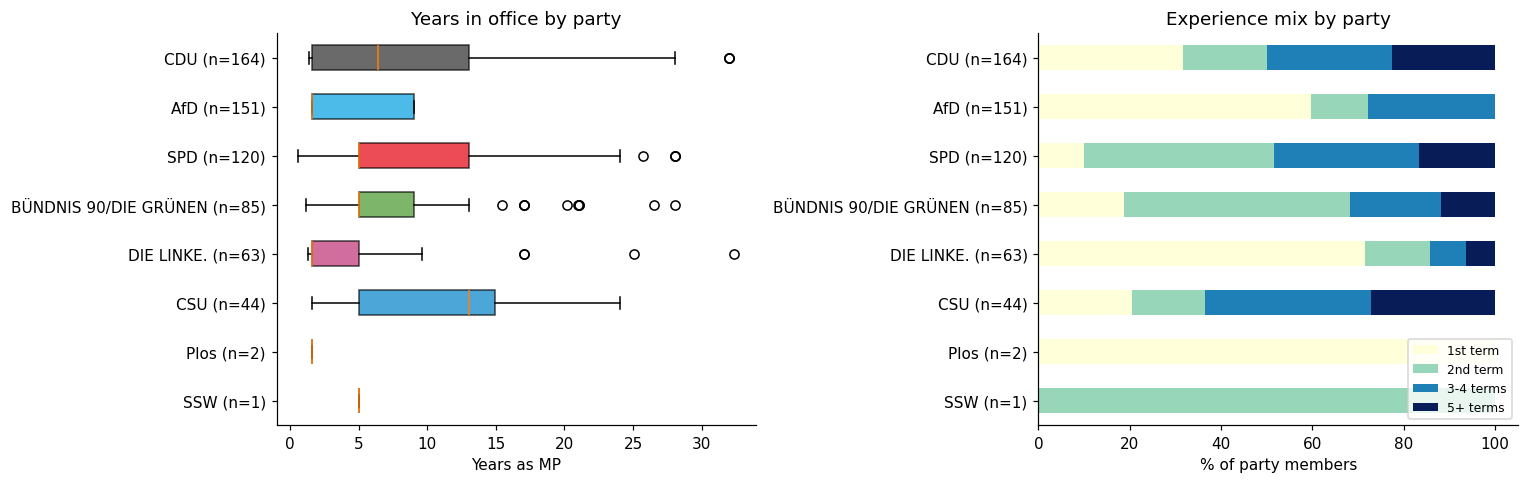

                      n_terms        years_total       
                         mean median        mean median
PARTEI_KURZ                                            
AfD                       1.7    1.0         4.1    1.6
BÜNDNIS 90/DIE GRÜNEN     2.6    2.0         7.3    5.0
CDU                       3.0    2.5         9.0    6.4
CSU                       3.5    4.0        11.1   13.0
DIE LINKE.                1.7    1.0         4.0    1.6
Plos                      1.0    1.0         1.6    1.6
SPD                       3.1    2.0         9.4    5.0
SSW                       2.0    2.0         5.0    5.0


In [38]:
n = df.PARTEI_KURZ.fillna("unknown").value_counts()
labels = [f"{p} (n={n[p]})" for p in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# years in office by party
data = [df.loc[df.PARTEI_KURZ.fillna("unknown") == p, "years_total"] for p in order]
bp = axes[0].boxplot(data, vert=False, patch_artist=True, tick_labels=labels)
for patch, p in zip(bp["boxes"], order):
    patch.set_facecolor(party_color(p)); patch.set_alpha(0.7)
axes[0].invert_yaxis(); axes[0].set_xlabel("Years as MP"); axes[0].set_title("Years in office by party")

# experience mix by party
bins = pd.cut(df.n_terms, [0, 1, 2, 4, 100], labels=["1st term", "2nd term", "3-4 terms", "5+ terms"])
mix = pd.crosstab(df.PARTEI_KURZ.fillna("unknown"), bins, normalize="index").mul(100).loc[order]
mix.index = labels
mix.plot(kind="barh", stacked=True, ax=axes[1], colormap="YlGnBu")
axes[1].invert_yaxis(); axes[1].set_xlabel("% of party members"); axes[1].set_title("Experience mix by party")
axes[1].legend(title=None, loc="lower right", fontsize=8)

plt.tight_layout(); plt.show()
print(df.groupby("PARTEI_KURZ")[["n_terms", "years_total"]].agg(["mean", "median"]).round(1))

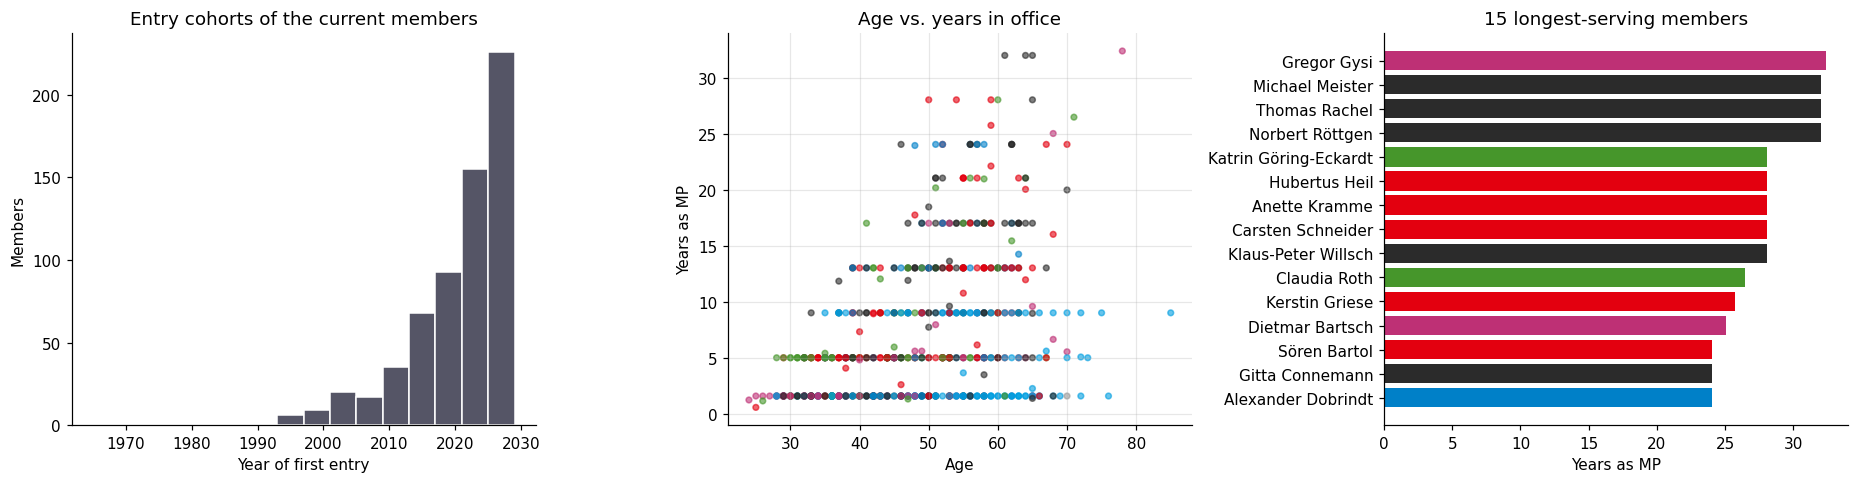

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# when did current members first enter?
axes[0].hist(df.first_year, bins=range(1965, 2031, 4), color="#556", edgecolor="white")
axes[0].set_xlabel("Year of first entry"); axes[0].set_ylabel("Members")
axes[0].set_title("Entry cohorts of the current members")

# age vs years in office
axes[1].scatter(df.Age, df.years_total, s=14, alpha=0.6, c=[party_color(p) for p in df.PARTEI_KURZ])
axes[1].set_xlabel("Age"); axes[1].set_ylabel("Years as MP"); axes[1].set_title("Age vs. years in office")
axes[1].grid(alpha=.3)

# longest-serving
top = df.nlargest(15, "years_total").iloc[::-1]
axes[2].barh(top.Name, top.years_total, color=[party_color(p) for p in top.PARTEI_KURZ])
axes[2].set_xlabel("Years as MP"); axes[2].set_title("15 longest-serving members")

plt.tight_layout(); plt.show()

## images

630 images read
       width  height  megapixels  aspect       kb
count  630.0   630.0      630.00  630.00   630.00
mean   564.0   752.0        0.42    0.75   102.20
std      0.0     0.0        0.00    0.00   192.40
min    564.0   752.0        0.42    0.75    23.95
25%    564.0   752.0        0.42    0.75    41.73
50%    564.0   752.0        0.42    0.75    49.10
75%    564.0   752.0        0.42    0.75    57.50
max    564.0   752.0        0.42    0.75  1145.62

Formats:
 format
JPEG    584
PNG      46
Name: count, dtype: int64

Most common sizes (w x h):
 width  height
564    752       630
dtype: int64


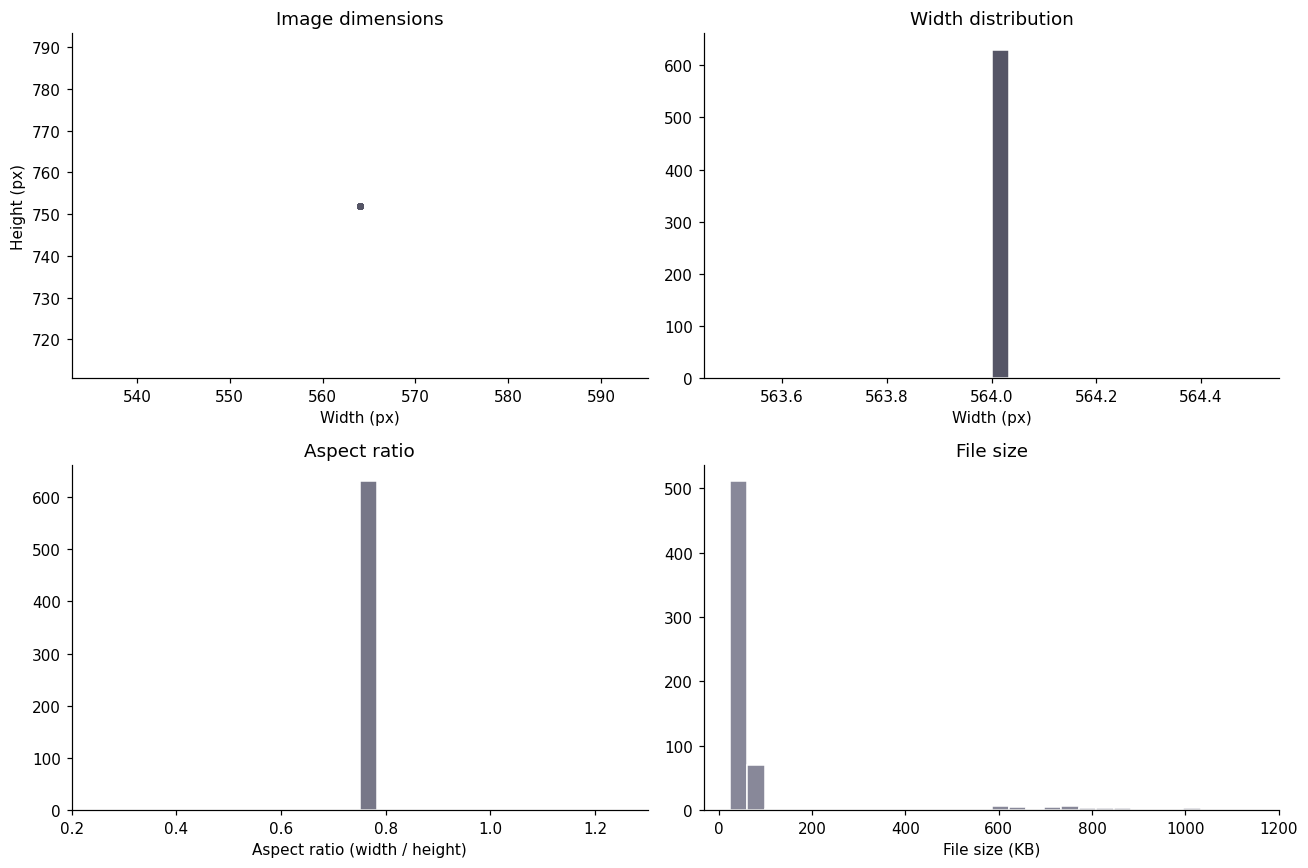


Smallest 5:
            Name  width  height        kb
    Gregor Gysi    564     752 55.567383
  Armin Laschet    564     752 49.582031
   Steffi Lemke    564     752 58.791016
Michael Meister    564     752 54.795898
 Friedrich Merz    564     752 42.849609

Largest 5:
            Name  width  height        kb
    Gregor Gysi    564     752 55.567383
  Armin Laschet    564     752 49.582031
   Steffi Lemke    564     752 58.791016
Michael Meister    564     752 54.795898
 Friedrich Merz    564     752 42.849609

Median width by party:
 PARTEI_KURZ
AfD                      564.0
BÜNDNIS 90/DIE GRÜNEN    564.0
CDU                      564.0
CSU                      564.0
DIE LINKE.               564.0
Plos                     564.0
SPD                      564.0
SSW                      564.0
Name: width, dtype: float64


In [ ]:
# rows = []
# for id_ in df.ID:
#     hits = glob.glob(os.path.join(IMG_DIR, f"{id_}.*"))
#     if not hits:
#         continue
#     with Image.open(hits[0]) as im:
#         rows.append({"ID": id_, "path": hits[0], "width": im.width, "height": im.height,
#                      "format": im.format, "kb": os.path.getsize(hits[0]) / 1024})
# img = pd.DataFrame(rows)
# img["megapixels"] = img.width * img.height / 1e6
# img["aspect"] = img.width / img.height
# img = img.merge(df[["ID", "Name", "PARTEI_KURZ"]], on="ID")

# print(len(img), "images read")
# print(img[["width", "height", "megapixels", "aspect", "kb"]].describe().round(2))
# print("\nFormats:\n", img.format.value_counts())
# print("\nMost common sizes (w x h):\n", img.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))

# fig, axes = plt.subplots(2, 2, figsize=(12, 8))
# axes[0, 0].scatter(img.width, img.height, s=12, alpha=0.5, color="#556")
# axes[0, 0].set_xlabel("Width (px)"); axes[0, 0].set_ylabel("Height (px)"); axes[0, 0].set_title("Image dimensions")
# axes[0, 1].hist(img.width, bins=30, color="#556", edgecolor="white")
# axes[0, 1].set_xlabel("Width (px)"); axes[0, 1].set_title("Width distribution")
# axes[1, 0].hist(img.aspect, bins=30, color="#778", edgecolor="white")
# axes[1, 0].set_xlabel("Aspect ratio (width / height)"); axes[1, 0].set_title("Aspect ratio")
# axes[1, 1].hist(img.kb, bins=30, color="#889", edgecolor="white")
# axes[1, 1].set_xlabel("File size (KB)"); axes[1, 1].set_title("File size")
# plt.tight_layout(); plt.show()

# print("\nSmallest 5:\n", img.nsmallest(5, "megapixels")[["Name", "width", "height", "kb"]].to_string(index=False))
# print("\nLargest 5:\n", img.nlargest(5, "megapixels")[["Name", "width", "height", "kb"]].to_string(index=False))
# print("\nMedian width by party:\n", img.groupby("PARTEI_KURZ").width.median())

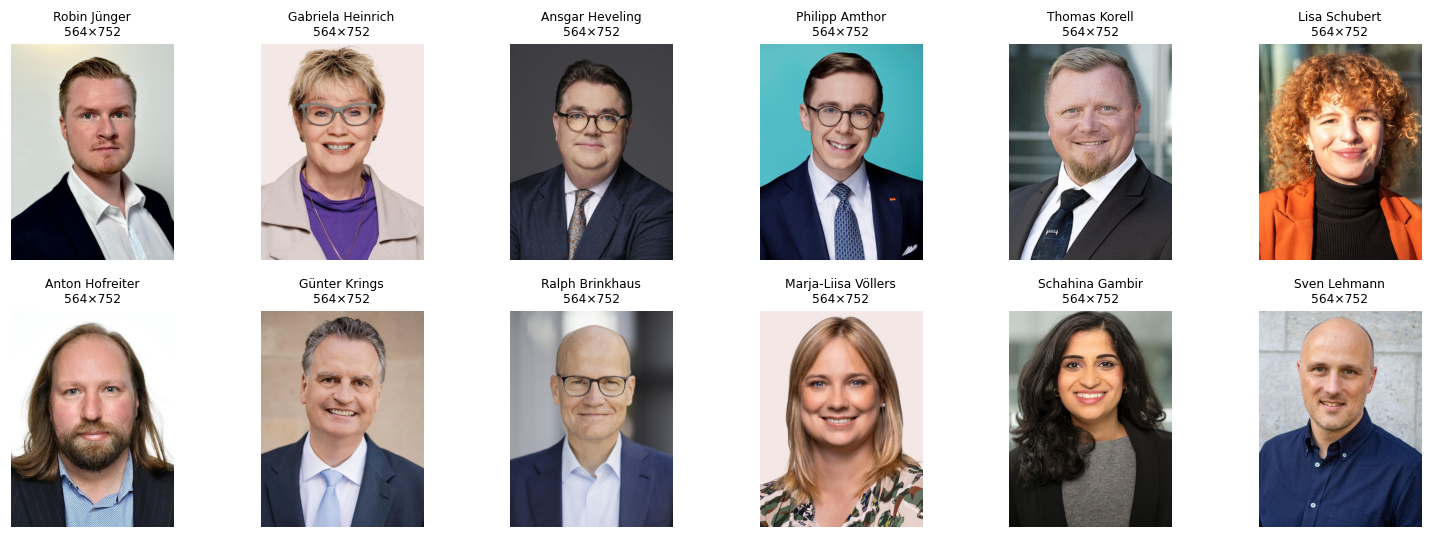

In [34]:
sample = img.sample(12, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r.path)); ax.axis("off")
    ax.set_title(f"{r.Name}\n{r.width}×{r.height}", fontsize=8)
plt.tight_layout(); plt.show()